In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix

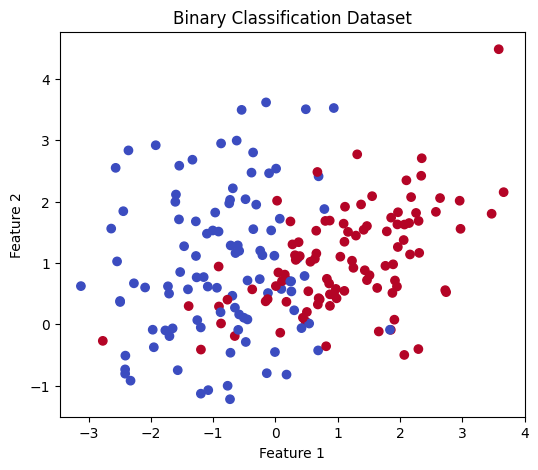

In [2]:
X, y = make_classification(
    n_samples=200,
    n_features=2,
    n_redundant=0,
    n_informative=2,
    n_clusters_per_class=1,
    random_state=42
)

plt.figure(figsize=(6,5))
plt.scatter(X[:,0], X[:,1], c=y, cmap='coolwarm')
plt.title("Binary Classification Dataset")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

In [3]:
scaler = StandardScaler()
X = scaler.fit_transform(X)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training Samples :", len(X_train))
print("Testing Samples :", len(X_test))

Training Samples : 160
Testing Samples : 40


In [4]:
class Perceptron:

    def __init__(self, learning_rate=0.01, epochs=100):
        self.lr = learning_rate
        self.epochs = epochs

    def step_function(self, x):
        return np.where(x >= 0, 1, 0)

    def fit(self, X, y):

        self.weights = np.zeros(X.shape[1])
        self.bias = 0

        for _ in range(self.epochs):

            for i in range(len(X)):

                linear_output = np.dot(X[i], self.weights) + self.bias
                prediction = self.step_function(linear_output)

                update = self.lr * (y[i] - prediction)

                self.weights += update * X[i]
                self.bias += update

    def predict(self, X):

        linear_output = np.dot(X, self.weights) + self.bias
        return self.step_function(linear_output)

In [5]:
model = Perceptron(learning_rate=0.01, epochs=100)

model.fit(X_train, y_train)

print("Learned Weights:")
print(model.weights)

print("\nLearned Bias:")
print(model.bias)

Learned Weights:
[ 0.01827128 -0.03314563]

Learned Bias:
0.019999999999999997


In [6]:
predictions = model.predict(X_test)

accuracy = accuracy_score(y_test, predictions)

print("Accuracy =", accuracy)

print("\nConfusion Matrix")

print(confusion_matrix(y_test, predictions))

Accuracy = 0.525

Confusion Matrix
[[ 4 19]
 [ 0 17]]


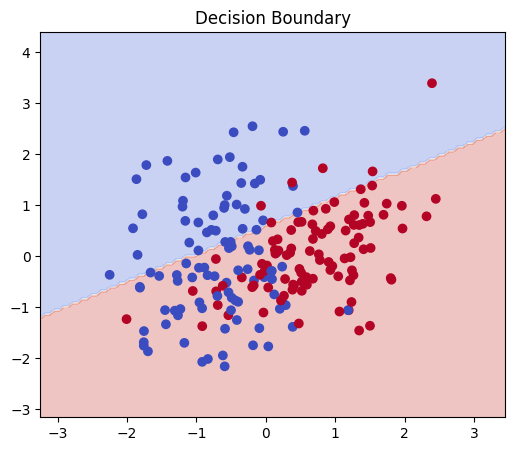

In [7]:
x1 = np.linspace(X[:,0].min()-1, X[:,0].max()+1, 100)
x2 = np.linspace(X[:,1].min()-1, X[:,1].max()+1, 100)

xx, yy = np.meshgrid(x1, x2)

grid = np.c_[xx.ravel(), yy.ravel()]

Z = model.predict(grid)

Z = Z.reshape(xx.shape)

plt.figure(figsize=(6,5))

plt.contourf(xx, yy, Z, alpha=0.3, cmap='coolwarm')

plt.scatter(X[:,0], X[:,1], c=y, cmap='coolwarm')

plt.title("Decision Boundary")

plt.show()

In [8]:
sample = X_test[0]

print("Sample Input :", sample)

print("Original Prediction :", model.predict([sample])[0])

model.weights += np.array([2, -2])

print("Modified Weights :", model.weights)

print("Prediction After Weight Change :", model.predict([sample])[0])

Sample Input : [-0.51833803  1.94461335]
Original Prediction : 0
Modified Weights : [ 2.01827128 -2.03314563]
Prediction After Weight Change : 0


In [9]:
model.bias += 2

print("Modified Bias :", model.bias)

print("Prediction After Bias Change :", model.predict([sample])[0])

Modified Bias : 2.02
Prediction After Bias Change : 0


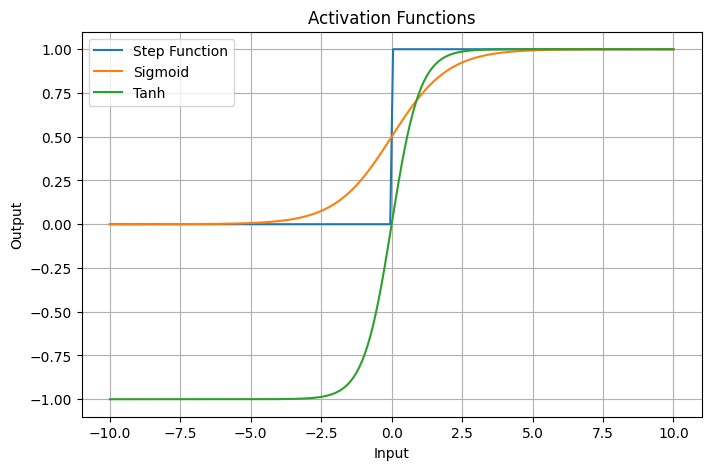

In [10]:
def step(x):
    return np.where(x >= 0, 1, 0)

def sigmoid(x):
    return 1/(1+np.exp(-x))

def tanh(x):
    return np.tanh(x)

x = np.linspace(-10,10,200)

plt.figure(figsize=(8,5))

plt.plot(x, step(x), label="Step Function")
plt.plot(x, sigmoid(x), label="Sigmoid")
plt.plot(x, tanh(x), label="Tanh")

plt.title("Activation Functions")

plt.xlabel("Input")

plt.ylabel("Output")

plt.grid(True)

plt.legend()

plt.show()

In [11]:
print("----- Observations -----")

print("1. Weights determine the importance of input features.")

print("2. Bias shifts the decision boundary.")

print("3. Increasing weights changes classification results.")

print("4. Changing bias shifts predictions.")

print("5. Step Function is suitable for binary classification.")

print("6. Sigmoid produces probability values between 0 and 1.")

print("7. Tanh outputs values between -1 and 1.")

----- Observations -----
1. Weights determine the importance of input features.
2. Bias shifts the decision boundary.
3. Increasing weights changes classification results.
4. Changing bias shifts predictions.
5. Step Function is suitable for binary classification.
6. Sigmoid produces probability values between 0 and 1.
7. Tanh outputs values between -1 and 1.
